# SMS Spam Classification using SVM — Enhanced Version

This notebook extends the original course project (`SMS_Spam_SVM (1).ipynb`), which used
word TF‑IDF + a linear SVM. The original is kept unchanged as the **baseline**, and every
new idea is measured against it.

**What's new**

| # | Enhancement | Why |
|---|---|---|
| 1 | Smarter text cleaning – links, phone numbers, prices and numbers become tokens (`urltoken`, `phonetoken`, `moneytoken`, `numtoken`) instead of being deleted | These are the strongest spam signals, and the original cleaner threw them away |
| 2 | Character n‑grams (2–5 chars) | Catch slang and disguised words: *fr33*, *txt*, *2nite*, *c-h-e-a-p* |
| 3 | Hand‑crafted meta features (length, digits, CAPS, `!`, URL/phone/price flags) | Test whether message *style* adds information |
| 4 | Comparison of 6 classifiers | Shows the SVM choice is justified |
| 5 | Ablation study | Measures what each enhancement adds |
| 6 | Bigger grid search (C, class weights, feature set), optimised for **F1** | Accuracy is misleading on imbalanced data (87% ham) |
| 7 | Probability calibration | The model says *"92% spam"* instead of just *Spam* |
| 8 | Full evaluation – confusion matrix, ROC and precision‑recall curves, threshold analysis | The original imported these functions but never used them |
| 9 | Explainability – top spam/ham features and per‑message explanations | See *why* a message is flagged |
| 10 | Error analysis + robustness test on new, hand‑written messages | Find the model's weak spots |
| 11 | Saved model, command‑line tool, Streamlit web app, unit tests | Turns the notebook into a usable project |

> **Run on Google Colab:**
> ```
> !git clone https://github.com/SSJemey/SMS_Spam_SVM.git
> %cd SMS_Spam_SVM
> !pip -q install -r requirements.txt
> ```

## 0. Setup

In [1]:
import json, warnings
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)

import train                       # all experiment code lives in train.py / src/
from src import plots
from src.model import load_data, build_baseline, calibrate, top_features, explain, predict_sms, save_model
from src.preprocessing import clean_text, clean_text_v2
from sklearn.model_selection import train_test_split

plots.apply_style()
show = lambda name, w=900: display(Image(filename=f"results/figures/{name}", width=w))

## 1. Load the data
Same Kaggle/UCI dataset as the original project (`data/spam.csv`). Duplicates are removed.

In [2]:
df = load_data()
print(df.shape)
df.head()

(5169, 3)


,label,message,target
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


## 2. Exploratory data analysis
Beyond the class balance, we look at *how* spam differs from normal messages.


1. Exploratory data analysis
Messages after removing duplicates: 5169  ->  {'ham': 4516, 'spam': 653}


                        ham    spam
Characters            70.46  137.89
Digits                 0.29   15.45
Upper‑case letters %   7.83   16.51
'!' marks              0.17    0.69
% url                  0.29   18.38
% phone                0.07   73.35
% money                0.24   50.38
% email                0.04    2.76


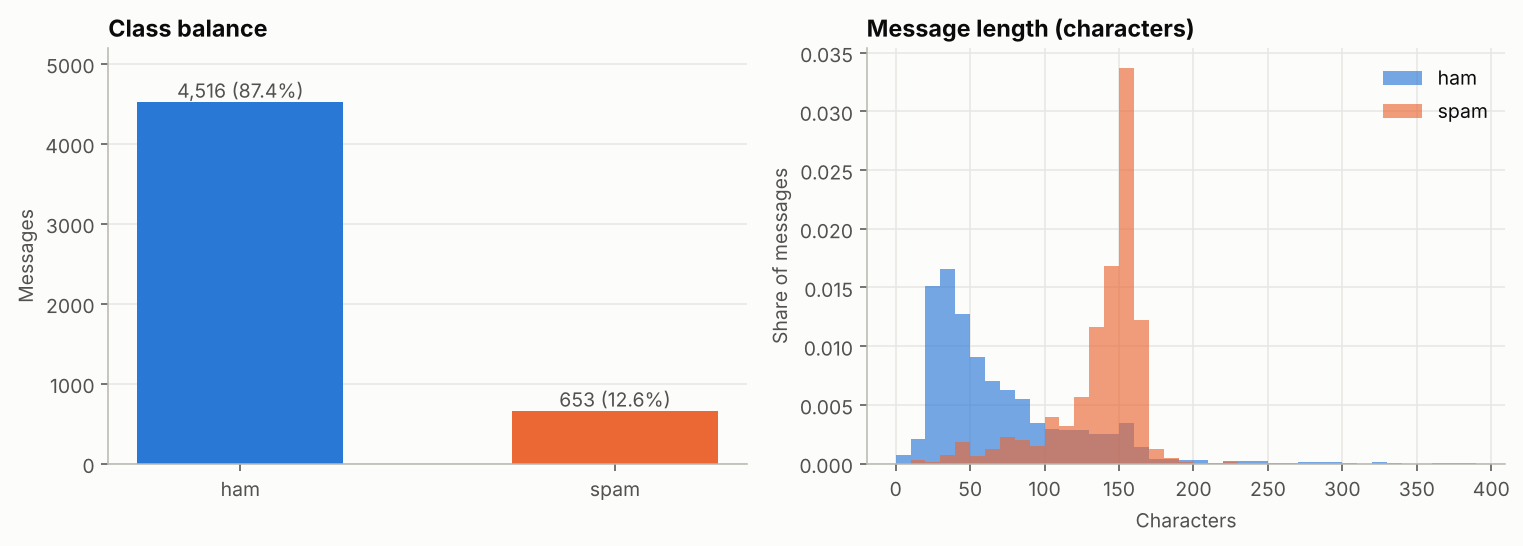

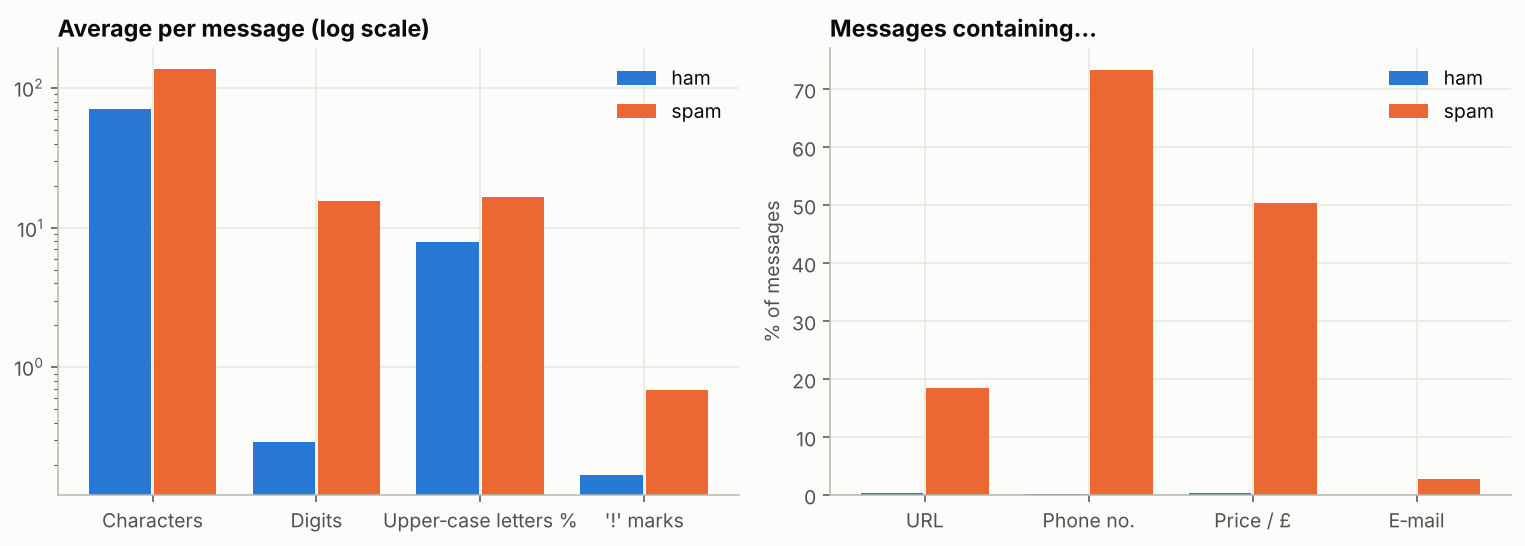

,ham,spam
Characters,70.46,137.89
Digits,0.29,15.45
Upper‑case letters %,7.83,16.51
'!' marks,0.17,0.69
% url,0.29,18.38
% phone,0.07,73.35
% money,0.24,50.38
% email,0.04,2.76


In [3]:
summary = train.eda(df)
show("01_class_balance_and_length.png")
show("02_meta_features.png")
summary.T

**Observations**
* The data is imbalanced: only ~12.6% of messages are spam, so *recall on spam* matters more than accuracy.
* Spam is about twice as long, and full of digits.
* ~73% of spam contains a phone number or short code, and ~50% mention a price — almost no ham does.
  The original cleaning step **deleted all numbers**, throwing this signal away.

## 3. Better text cleaning
Original vs enhanced cleaner on a few spam messages:

In [4]:
examples = df[df.label == "spam"].message.sample(5, random_state=1).tolist() + \
           ["Visit www.win-now.com or email claims@prize.com for your £250 reward"]
pd.DataFrame({"message": examples,
              "original clean_text": [clean_text(m) for m in examples],
              "enhanced clean_text_v2": [clean_text_v2(m) for m in examples]})

,message,original clean_text,enhanced clean_text_v2
0,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cs...",oh god ive found number im glad text back xafter msg cst std ntwk chg å£,oh god ive found number im glad text back xafter msg cst std ntwk chg å moneytoken
1,Do you want a New Nokia 3510i Colour Phone Delivered Tomorrow? With 200 FREE minutes t...,want new nokia colour phone delivered tomorrow free minute mobile free text free camco...,want new nokia numtoken colour phone delivered tomorrow numtoken free minute mobile nu...
2,You have WON a guaranteed å£1000 cash or a å£2000 prize. To claim yr prize call our cu...,guaranteed å£ cash å£ prize claim yr prize call customer service representative pm cost p,guaranteed å moneytoken cash å moneytoken prize claim yr prize call customer service r...
3,We tried to contact you re your reply to our offer of a Video Handset? 750 anytime any...,tried contact reply offer video handset anytime network min unlimited text camcorder r...,tried contact reply offer video handset numtoken anytime network min unlimited text ca...
4,Ringtone Club: Get the UK singles chart on your mobile each week and choose any top qu...,ringtone club get uk single chart mobile week choose top quality ringtone message free...,ringtone club get uk single chart mobile week choose top quality ringtone message free...
5,Visit www.win-now.com or email claims@prize.com for your £250 reward,visit email £ reward,visit urltoken email emailtoken moneytoken reward


## 4. Train / test split
Identical to the original (80/20, stratified, `random_state=42`) so results are directly comparable.

In [5]:
X, y = df["message"], df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4135,)  Test: (1034,)


## 5. Which classifier is best?
Six classifiers, all on the same word + character TF‑IDF features, 5‑fold cross‑validation on the training set.


2. Comparing classifiers (same word + character TF‑IDF features)


Multinomial Naive Bayes    F1=0.9572  recall=0.9406  (8s)


Logistic Regression        F1=0.9515  recall=0.9233  (4s)


K‑Nearest Neighbours       F1=0.9179  recall=0.8601  (4s)


Random Forest              F1=0.9435  recall=0.9003  (15s)


SVM (RBF kernel)           F1=0.9489  recall=0.9118  (40s)


SVM (linear)               F1=0.9587  recall=0.9367  (4s)


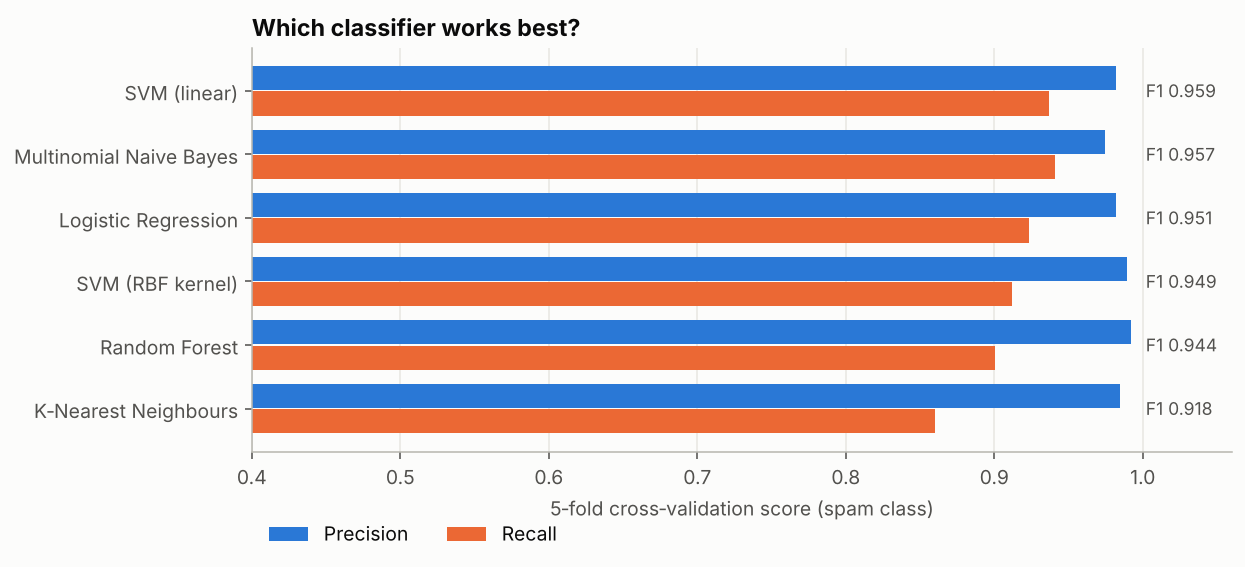

,model,accuracy,precision,recall,f1,f1_std,fit_seconds
5,SVM (linear),0.9898,0.9820,0.9367,0.9587,0.0094,1.0549
0,Multinomial Naive Bayes,0.9894,0.9747,0.9406,0.9572,0.0127,1.9656
1,Logistic Regression,0.9881,0.9818,0.9233,0.9515,0.0106,1.2281
4,SVM (RBF kernel),0.9877,0.9896,0.9118,0.9489,0.0150,11.4810
3,Random Forest,0.9865,0.9918,0.9003,0.9435,0.0141,5.0296
2,K‑Nearest Neighbours,0.9807,0.9849,0.8601,0.9179,0.0182,0.9191


In [6]:
clf_table = train.compare_classifiers(X_train, y_train)
show("03_classifier_comparison.png")
clf_table.round(4)

The **linear SVM** has the best F1 and is also one of the fastest. Text data is very high‑dimensional and close to linearly separable, which is exactly where linear SVMs shine. The RBF kernel is slower and no better.

## 6. Ablation study — what does each enhancement add?
Starting from the original pipeline, we add one enhancement at a time (5‑fold CV on the training set).


3. Ablation study – what does each enhancement add?


1. Baseline (original project)                     F1=0.9036  recall=0.8468  precision=0.9700


2. + better cleaning (keep URL/phone/£ tokens)     F1=0.9538  recall=0.9310  precision=0.9780


3. + character n‑grams                             F1=0.9587  recall=0.9367  precision=0.9820


4. + meta features                                 F1=0.9579  recall=0.9386  precision=0.9783


5. + balanced class weights                        F1=0.9533  recall=0.9386  precision=0.9687


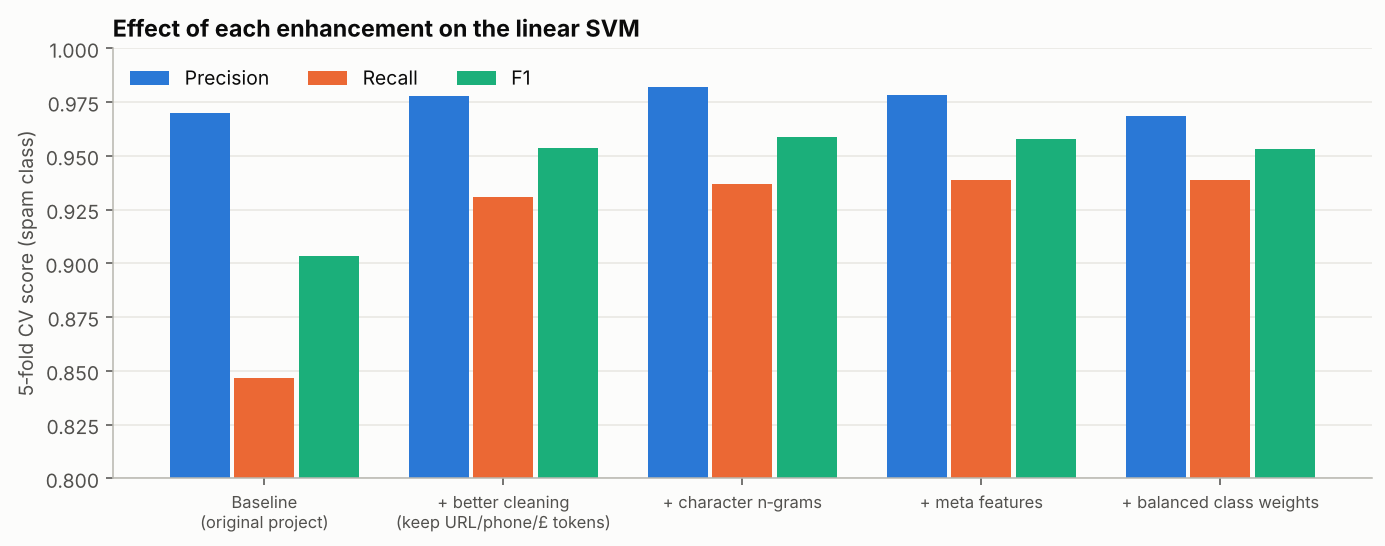

,step,accuracy,precision,recall,f1
0,1. Baseline (original project),0.9773,0.9700,0.8468,0.9036
1,2. + better cleaning (keep URL/phone/£ tokens),0.9886,0.9780,0.9310,0.9538
2,3. + character n‑grams,0.9898,0.9820,0.9367,0.9587
3,4. + meta features,0.9896,0.9783,0.9386,0.9579
4,5. + balanced class weights,0.9884,0.9687,0.9386,0.9533


In [7]:
abl_table = train.ablation(X_train, y_train)
show("04_ablation_study.png")
abl_table.round(4)

* **Keeping URL/phone/price tokens** gives the biggest jump: spam recall rises by about 8 points.
* **Character n‑grams** add a further gain in both precision and recall.
* **Meta features** don't help on top of these — the information they carry (digits, links, prices) is already captured by the tokens and n‑grams. This is a useful negative result.
* **Balanced class weights** trade a little precision for recall; the grid search below decides whether that's worth it.

## 7. Hyper‑parameter tuning
Grid search over `C`, `class_weight` and whether to include meta features, optimising **F1** (not accuracy).

In [8]:
best_pipe, best_params, best_cv_f1 = train.tune(X_train, y_train)
pd.read_csv("results/grid_search_results.csv").head(8)


4. Hyper‑parameter tuning (GridSearchCV, optimising F1)


Best parameters: {'C': 1, 'class_weight': 'balanced', 'meta_features': False}
Best CV F1: 0.9610


,param_svm__C,param_svm__class_weight,meta,mean_test_score,std_test_score,rank_test_score
0,1.0,balanced,False,0.960953,0.010350,1
1,3.0,balanced,False,0.960847,0.010474,2
2,10.0,balanced,False,0.960847,0.010474,2
3,3.0,NaN,False,0.960757,0.010524,4
4,10.0,NaN,False,0.960757,0.010524,4
5,0.3,balanced,False,0.960351,0.007320,6
6,10.0,balanced,True,0.958872,0.006709,7
7,10.0,NaN,True,0.958872,0.006709,7


## 8. Final model and test‑set evaluation
The tuned SVM is wrapped in `CalibratedClassifierCV` so it outputs a spam probability. The baseline is re‑trained exactly as in the original notebook.


5. Final evaluation on the held‑out test set


               Baseline (original)  Enhanced
accuracy                    0.9836    0.9903
precision                   0.9831    0.9764
recall                      0.8855    0.9466
f1                          0.9317    0.9612
roc_auc                     0.9959    0.9986
avg_precision               0.9818    0.9934
tn                        901.0000  900.0000
fp                          2.0000    3.0000
fn                         15.0000    7.0000
tp                        116.0000  124.0000



Misclassified test messages: 10 (saved to results/misclassified_messages.csv)


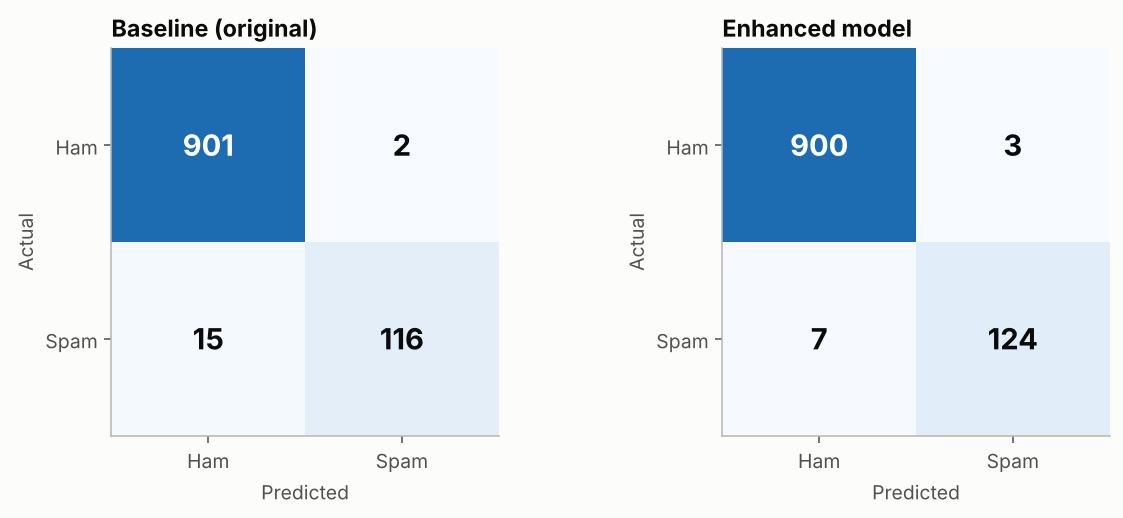

In [9]:
baseline = build_baseline().fit(X_train, y_train)
final = calibrate(best_pipe, X_train, y_train)
m_base, m_final = train.evaluate(baseline, final, X_test, y_test)
show("05_confusion_matrices.png", 700)

In [10]:
comparison = pd.DataFrame({"Baseline (original)": m_base, "Enhanced": m_final})
comparison

,Baseline (original),Enhanced
accuracy,0.983559,0.990329
precision,0.983051,0.976378
recall,0.885496,0.946565
f1,0.931727,0.961240
roc_auc,0.995866,0.998597
avg_precision,0.981812,0.993405
tn,901.000000,900.000000
fp,2.000000,3.000000
fn,15.000000,7.000000
tp,116.000000,124.000000


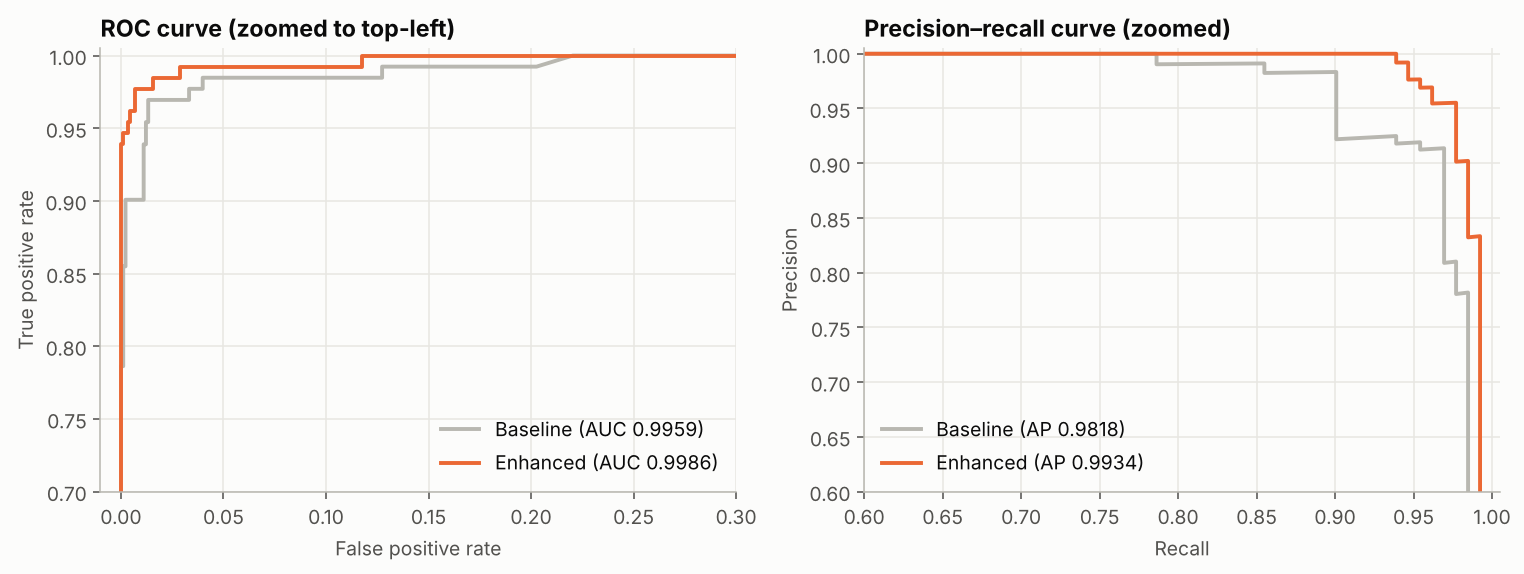

In [11]:
show("06_roc_pr_curves.png")

### Choosing the threshold
The default cut‑off is 0.5. Lowering it catches more spam at the cost of more false alarms; the web app has a slider for this.

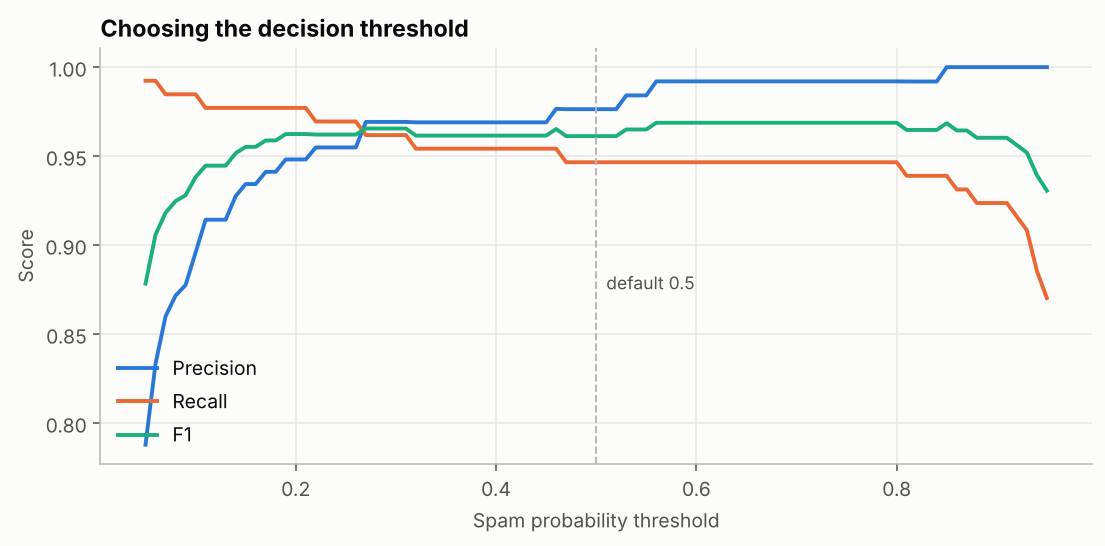

In [12]:
show("07_threshold_tradeoff.png", 700)

## 9. Explainability
A linear SVM is interpretable: each feature has one weight. Positive weights push towards spam.

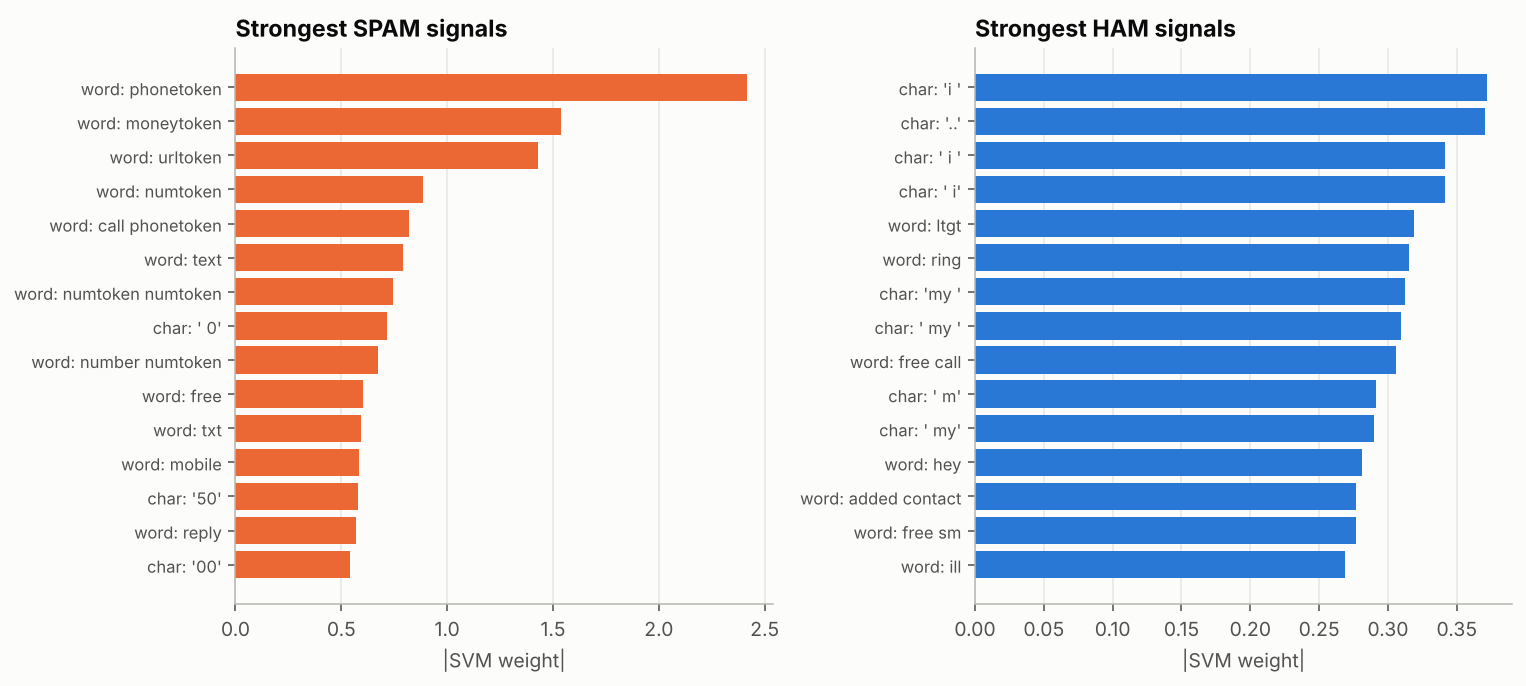

In [13]:
train.plot_top_features(final)
show("08_top_features.png")

Explaining a single prediction (contribution = feature value × weight):

In [14]:
msg = "URGENT! You have won a £900 prize. Call 09061701461 to claim"
print(predict_sms(final, msg))
explain(final, msg, n=10)

('Spam', 0.9998534095077789)


,feature,contribution
0,word: phonetoken,0.496340
1,word: moneytoken,0.348674
2,word: call phonetoken,0.211668
3,word: claim,0.132332
4,word: prize,0.102307
5,word: urgent,0.070462
6,word: call,0.045307
7,char: ' 0',0.043648
8,char: '90',0.042135
9,word: phonetoken claim,0.036974


## 10. Error analysis
Every test message the enhanced model got wrong:

In [15]:
pd.read_csv("results/misclassified_messages.csv")

,message,actual,predicted,spam_probability,error_type
0,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,1,0,0.0191,missed spam (false negative)
1,In The Simpsons Movie released in July 2007 name the band that died at the start of th...,1,0,0.0606,missed spam (false negative)
2,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0,0.1046,missed spam (false negative)
3,SMS. ac sun0819 posts HELLO:\You seem cool,1,0,0.2197,missed spam (false negative)
4,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am t...",1,0,0.2602,missed spam (false negative)
5,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and...,1,0,0.3116,missed spam (false negative)
6,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time...,1,0,0.4609,missed spam (false negative)
7,Your bill at 3 is å£33.65 so thats not bad!,0,1,0.5296,ham flagged as spam (false positive)
8,Lmao!nice 1,0,1,0.5518,ham flagged as spam (false positive)
9,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0,1,0.8452,ham flagged as spam (false positive)


**What goes wrong?**
* **Missed spam** is mostly spam *without* a phone number or link – adult content, quiz/joke messages and promotions written like normal chat. The model leans heavily on numbers and links, so this kind of spam slips through.
* **False alarms** are ham messages that talk about **money** (a bill amount, a tour price with `$95/pax`, a deposit) – they look like spam offers.
* One message shows an encoding problem in the dataset: `£` was stored as `å£`.

## 11. Robustness test on new messages
12 messages written for this project (not in the dataset), several using filter‑dodging tricks.

In [16]:
robust = train.robustness(baseline, final)


6. Robustness test on new, hand‑written messages
                                                                   message actual baseline enhanced  enhanced_spam_prob
                        FR33 entry! W1N a £500 prize, txt WIN to 80086 now   Spam     Spam     Spam               0.998
    Congratulations ur awarded 2 nights holiday. Call 09061743810 to claim   Spam     Spam     Spam               0.991
Your account has been suspended. Verify now at www.secure-login-update.com   Spam      Ham     Spam               0.850
       U have been selected for a CA$H reward of $1000. Reply YES to claim   Spam     Spam     Spam               0.981
       URGENT! Your mobile number has won a cash bonus. Ring 0800 123 4567   Spam     Spam     Spam               0.983
           Get c-h-e-a-p loans today, no credit check!! text LOAN to 61234   Spam      Ham     Spam               0.795
                        Hey, can you send me the notes from today's class?    Ham      Ham      Ham           

The enhanced model catches the phishing link and the `c-h-e-a-p` disguise that the baseline misses.
It wrongly flags the **OTP message**: the dataset is from 2011, before one‑time passwords were common,
so any message with a 6‑digit number looks like spam to it. **This shows the limits of an old dataset**,
and it's a good argument for retraining on modern SMS data.

## 12. Cross‑validation on the full dataset
The same check as the original notebook, now with spam‑class precision, recall and F1 too.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
cv = {name: cross_validate(m, X, y, cv=train.CV, scoring=train.SCORING, n_jobs=-1)
      for name, m in [("baseline", build_baseline()), ("enhanced", clone(best_pipe))]}
pd.DataFrame({k: {m: v[f"test_{m}"].mean() for m in train.SCORING} for k, v in cv.items()}).round(4)

,baseline,enhanced
accuracy,0.9808,0.9907
precision,0.9678,0.9796
recall,0.8775,0.9464
f1,0.9204,0.9625


## 13. Save the model and predict

In [18]:
save_model(final, {"best_params": best_params, "best_cv_f1": best_cv_f1, "test_metrics": m_final,
                   "train_size": len(X_train), "test_size": len(X_test)})

for m in ["Congratulations! You have won a free iPhone. Click here now.",
          "Hi, are we meeting tomorrow at 3 PM?",
          "Your account has been suspended. Verify now at www.secure-login-update.com"]:
    label, p = predict_sms(final, m)
    print(f"{label:4s}  {p:6.1%}  {m}")

Spam   52.8%  Congratulations! You have won a free iPhone. Click here now.
Ham     0.2%  Hi, are we meeting tomorrow at 3 PM?
Spam   85.0%  Your account has been suspended. Verify now at www.secure-login-update.com


## 14. Conclusions

* The original project's **98.4% accuracy hid a weakness**: it missed about 1 in 9 spam messages,
  because the cleaning step deleted the phone numbers, prices and links that make spam recognisable.
* Keeping those signals as tokens and adding character n‑grams **halves the number of missed spam
  messages** while keeping false alarms very low.
* The linear SVM is the best of six classifiers on this task, and it is fast and easy to explain.
* Hand‑crafted meta features did not help once the text features were improved.
* The model's main limitation is the **age of the dataset** (e.g. OTP messages are flagged as spam).

**Try it:** `streamlit run app.py` for the web app, or `python predict.py "your message"` from the terminal.